In [1]:
import kagglehub
import matplotlib.pyplot as plt
import pandas as pd
pd.set_option("display.max.columns", None)


/Users/mohimohi/STA258_GP/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# path = kagglehub.dataset_download("bwandowando/clash-royale-season-18-dec-0320-dataset", output_dir="./data")
# print(path)

### Dataset background
- Clash Royale Season 18, which lasted from December 9th 2018 to January 4th 2019.
- We will be only using the dataset from the last day, when all players have "converged" to their true trophy count.

### Rough EDA procedure
1. Investigate what each column represents (e.g. what is each gamemodeId?)
2. Investigate which columns we should keep
3. Clear up null values or replace them with reasonable values

In [3]:
# first batch
df1 = pd.read_csv("data/BattlesStaging_01042021_WL_tagged/BattlesStaging_01042021_WL_tagged.csv")
# df2 = pd.read_csv("data/BattlesStaging_01032021_WL_tagged/BattlesStaging_01032021_WL_tagged.csv")
# df3 = pd.read_csv("data/BattlesStaging_01022021_WL_tagged/BattlesStaging_01022021_WL_tagged.csv")
# df4 = pd.read_csv("data/BattlesStaging_01012021_WL_tagged/BattlesStaging_01012021_WL_tagged.csv")
# df5 = pd.read_csv("data/BattlesStaging_12312021_WL_tagged/BattlesStaging_12312021_WL_tagged.csv")
# df6 = pd.read_csv("data/BattlesStaging_12302021_WL_tagged/BattlesStaging_12302021_WL_tagged.csv")

df = pd.concat([df1])

del df1

In [4]:
df.head()

,Unnamed: 0,battleTime,arena.id,gameMode.id,average.startingTrophies,winner.tag,winner.startingTrophies,winner.trophyChange,winner.crowns,winner.kingTowerHitPoints,winner.princessTowersHitPoints,winner.clan.tag,winner.clan.badgeId,loser.tag,loser.startingTrophies,loser.trophyChange,loser.crowns,loser.kingTowerHitPoints,loser.clan.tag,loser.clan.badgeId,loser.princessTowersHitPoints,tournamentTag,winner.card1.id,winner.card1.level,winner.card2.id,winner.card2.level,winner.card3.id,winner.card3.level,winner.card4.id,winner.card4.level,winner.card5.id,winner.card5.level,winner.card6.id,winner.card6.level,winner.card7.id,winner.card7.level,winner.card8.id,winner.card8.level,winner.cards.list,winner.totalcard.level,winner.troop.count,winner.structure.count,winner.spell.count,winner.common.count,winner.rare.count,winner.epic.count,winner.legendary.count,winner.elixir.average,loser.card1.id,loser.card1.level,loser.card2.id,loser.card2.level,loser.card3.id,loser.card3.level,loser.card4.id,loser.card4.level,loser.card5.id,loser.card5.level,loser.card6.id,loser.card6.level,loser.card7.id,loser.card7.level,loser.card8.id,loser.card8.level,loser.cards.list,loser.totalcard.level,loser.troop.count,loser.structure.count,loser.spell.count,loser.common.count,loser.rare.count,loser.epic.count,loser.legendary.count,loser.elixir.average
0,0,2021-01-03 21:03:56+00:00,54000050.0,72000201.0,5899.5,#P2V090LU2,5905.0,29.0,1.0,5832.0,"[3208, 1411]",#8UCQGRL0,16000110.0,#YPJLYY0R,5894.0,-29.0,0.0,5762.0,#YQC2UUGY,16000010.0,[3240],NaN,26000023,13,28000003,13,28000012,13,26000010,13,26000000,13,27000006,13,27000008,13,28000011,13,"[26000000, 26000010, 26000023, 27000006, 27000...",104,3,2,3,3,1,2,2,3.500,28000011,13,28000000,13,26000001,13,27000006,13,26000038,13,27000008,13,26000030,13,26000010,13,"[26000001, 26000010, 26000030, 26000038, 27000...",104,4,2,2,4,2,1,1,2.875
1,1,2021-01-03 21:04:05+00:00,54000050.0,72000201.0,5323.5,#PY89GYR,5317.0,31.0,2.0,5832.0,[289],#Q9VLYPRG,16000109.0,#P2Y80U9V,5330.0,-31.0,1.0,4265.0,#2YJL88YP,16000178.0,NaN,NaN,28000010,13,27000009,13,28000009,13,28000015,13,26000015,13,28000012,13,26000023,13,26000000,13,"[26000000, 26000015, 26000023, 27000009, 28000...",104,3,1,4,1,1,4,2,3.375,26000026,13,26000041,13,26000030,13,28000003,13,28000004,13,27000003,13,26000011,13,28000001,13,"[26000011, 26000026, 26000030, 26000041, 27000...",104,4,1,3,3,3,1,1,3.500
2,2,2021-01-03 21:04:11+00:00,54000050.0,72000201.0,6413.0,#8P2CL28CP,6416.0,29.0,1.0,5832.0,"[562, 3668]",#8UCQGRL0,16000110.0,#RUQP0P98,6410.0,-29.0,0.0,5569.0,#929JYYJ,16000136.0,[3668],NaN,27000002,13,26000041,13,28000000,13,26000014,13,28000011,13,26000019,13,26000000,13,26000056,13,"[26000000, 26000014, 26000019, 26000041, 26000...",104,5,1,2,4,2,1,1,3.125,26000003,13,26000035,13,26000017,13,26000012,13,26000006,13,26000037,13,26000040,13,28000017,13,"[26000003, 26000006, 26000012, 26000017, 26000...",104,7,0,1,1,3,2,2,3.875
3,3,2021-01-03 21:04:43+00:00,54000050.0,72000201.0,5674.5,#GGLP992G,5651.0,34.0,2.0,4230.0,[838],#2J80CR9,16000025.0,#8JR89RG,5698.0,-34.0,1.0,5076.0,#289P0CVC,16000126.0,NaN,NaN,26000051,13,26000042,13,26000037,13,26000044,13,28000009,13,26000061,13,26000050,13,28000011,13,"[26000037, 26000042, 26000044, 26000050, 26000...",104,6,0,2,0,0,2,6,3.625,26000009,13,26000015,13,26000063,13,26000054,13,26000035,13,26000039,13,28000012,13,28000015,13,"[26000009, 26000015, 26000035, 26000039, 26000...",104,6,0,2,0,1,6,1,4.250
4,4,2021-01-03 21:04:44+00:00,54000050.0,72000201.0,5094.0,#2VR2GRQ9R,5091.0,30.0,2.0,4310.0,[1804],#2JUJPLG8,16000004.0,#UC2R9L92,5097.0,-30.0,1.0,1780.0,#8PVCYJ,16000053.0,NaN,NaN,26000039,13,28000012,13,28000015,13,28000007,13,26000009,13,26000015,13,26000035,13,26000048,13,"[26000009, 26000015, 26000035, 26000039, 26000...",104,5,0,3,0,1,5,2,4.250,26000018,13,26000012,13,26000021,13,26000017,13,26000014,13,26000024,13,26000016,13,28000008,13,"[26000012, 26000014, 26000016, 26000017, 26000...",104,7,0,1,2,4,2,0,4.125


In [5]:
metadata = ["winner.clan.tag", "winner.clan.badgeId", "winner.kingTowerHitPoints", "winner.princessTowersHitPoints", "loser.clan.tag", "loser.clan.badgeId", "loser.kingTowerHitPoints", "loser.princessTowersHitPoints", "tournamentTag"]
card_data = []
for player in ["winner", "loser"]:
    card_data.append(f"{player}.totalcard.level")
    card_data.append(f"{player}.troop.count")
    card_data.append(f"{player}.structure.count")
    card_data.append(f"{player}.spell.count")
    card_data.append(f"{player}.common.count")
    card_data.append(f"{player}.rare.count")
    card_data.append(f"{player}.epic.count")
    card_data.append(f"{player}.legendary.count")
    card_data.append(f"{player}.elixir.average")
    card_data.append(f"{player}.cards.list")
    for i in range(1,9):
        card_data.append(f"{player}.card{i}.id")
        card_data.append(f"{player}.card{i}.level")

combined_metadata = metadata + card_data
cleaned = df.drop(columns=combined_metadata)
cleaned.head()

,Unnamed: 0,battleTime,arena.id,gameMode.id,average.startingTrophies,winner.tag,winner.startingTrophies,winner.trophyChange,winner.crowns,loser.tag,loser.startingTrophies,loser.trophyChange,loser.crowns
0,0,2021-01-03 21:03:56+00:00,54000050.0,72000201.0,5899.5,#P2V090LU2,5905.0,29.0,1.0,#YPJLYY0R,5894.0,-29.0,0.0
1,1,2021-01-03 21:04:05+00:00,54000050.0,72000201.0,5323.5,#PY89GYR,5317.0,31.0,2.0,#P2Y80U9V,5330.0,-31.0,1.0
2,2,2021-01-03 21:04:11+00:00,54000050.0,72000201.0,6413.0,#8P2CL28CP,6416.0,29.0,1.0,#RUQP0P98,6410.0,-29.0,0.0
3,3,2021-01-03 21:04:43+00:00,54000050.0,72000201.0,5674.5,#GGLP992G,5651.0,34.0,2.0,#8JR89RG,5698.0,-34.0,1.0
4,4,2021-01-03 21:04:44+00:00,54000050.0,72000201.0,5094.0,#2VR2GRQ9R,5091.0,30.0,2.0,#UC2R9L92,5097.0,-30.0,1.0


In [6]:
cleaned.describe()

,Unnamed: 0,arena.id,gameMode.id,average.startingTrophies,winner.startingTrophies,winner.trophyChange,winner.crowns,loser.startingTrophies,loser.trophyChange,loser.crowns
count,1.105943e+06,1.105943e+06,1.105943e+06,1.105943e+06,1.105943e+06,1.105943e+06,1.105943e+06,1.105943e+06,1.105943e+06,1.105943e+06
mean,5.529710e+05,5.400005e+07,7.200020e+07,4.870041e+03,4.870348e+03,2.947622e+01,1.776480e+00,4.869734e+03,-2.930886e+01,3.177370e-01
std,3.192584e+05,8.117032e+00,2.015525e+00,7.803038e+02,7.803361e+02,1.506827e+00,8.456224e-01,7.803646e+02,2.393276e+00,5.063730e-01
min,0.000000e+00,5.400000e+07,7.200001e+07,2.500000e+01,2.400000e+01,3.000000e+00,1.000000e+00,2.400000e+01,-5.600000e+01,0.000000e+00
25%,2.764855e+05,5.400005e+07,7.200020e+07,4.444500e+03,4.445000e+03,2.900000e+01,1.000000e+00,4.444000e+03,-3.000000e+01,0.000000e+00
50%,5.529710e+05,5.400005e+07,7.200020e+07,4.819000e+03,4.819000e+03,3.000000e+01,2.000000e+00,4.819000e+03,-3.000000e+01,0.000000e+00
75%,8.294565e+05,5.400005e+07,7.200020e+07,5.299000e+03,5.299000e+03,3.000000e+01,3.000000e+00,5.299000e+03,-2.900000e+01,1.000000e+00
max,1.105942e+06,5.400005e+07,7.200020e+07,7.661500e+03,7.678000e+03,5.600000e+01,3.000000e+00,7.685000e+03,-1.000000e+00,2.000000e+00


In [7]:
# cleaned.drop(columns=["Unnamed: 0"]).hist(figsize=(15, 15), layout=(-1,4), bins=30, edgecolor="black")
# plt.tight_layout()
# plt.show()

# Reformatting the data
We now want to create a table where the rows are:
- User ID
- Start time of the match
- Trophy count before the match
- Outcome of the match

We eventually want to be able to group by User ID and sort all games by date.
Each row in the cleaned table contains a single unique game, where there is a winner and a loser.
For each row, append to the new df the User ID, start time, trophy count, and outcome.

We can vectorize this operation with `df.melt(id_vars, value_vars)`:
it is essentially just $$[(id_{vars})]\times[value_{vars}]=[(id_1+\dots+id_m)]\times[value_1+\dots+value_n]$$
$$=(id_1+\dots+id_m)(value_1)+\dots+(id_1+\dots+id_n)(value_n)$$

where multiplication of $()$ is concatenation and multiplcation of $[]$ is distributive in the usual real number sense.

In [8]:
temp = cleaned.melt(id_vars=["battleTime","winner.startingTrophies", "loser.startingTrophies"], value_vars=["winner.tag", "loser.tag"], var_name="outcome", value_name="user")

reshaped = temp.dropna()
print(f"removed {temp.size - reshaped.size} rows that contained NA")
reshaped.head()

removed 0 rows that contained NA


,battleTime,winner.startingTrophies,loser.startingTrophies,outcome,user
0,2021-01-03 21:03:56+00:00,5905.0,5894.0,winner.tag,#P2V090LU2
1,2021-01-03 21:04:05+00:00,5317.0,5330.0,winner.tag,#PY89GYR
2,2021-01-03 21:04:11+00:00,6416.0,6410.0,winner.tag,#8P2CL28CP
3,2021-01-03 21:04:43+00:00,5651.0,5698.0,winner.tag,#GGLP992G
4,2021-01-03 21:04:44+00:00,5091.0,5097.0,winner.tag,#2VR2GRQ9R


In [9]:
def trophies(row):
    if row["outcome"] == "winner.tag":
        return row["winner.startingTrophies"]
    else:
        return row["loser.startingTrophies"]

reshaped["trophies"] = reshaped.apply(trophies, axis=1)
reshaped.head()

,battleTime,winner.startingTrophies,loser.startingTrophies,outcome,user,trophies
0,2021-01-03 21:03:56+00:00,5905.0,5894.0,winner.tag,#P2V090LU2,5905.0
1,2021-01-03 21:04:05+00:00,5317.0,5330.0,winner.tag,#PY89GYR,5317.0
2,2021-01-03 21:04:11+00:00,6416.0,6410.0,winner.tag,#8P2CL28CP,6416.0
3,2021-01-03 21:04:43+00:00,5651.0,5698.0,winner.tag,#GGLP992G,5651.0
4,2021-01-03 21:04:44+00:00,5091.0,5097.0,winner.tag,#2VR2GRQ9R,5091.0


In [10]:
def rename_outcome(row):
    if row["outcome"] == "winner.tag":
        return "win"
    return "loss"

reshaped["outcome"] = reshaped.apply(rename_outcome, axis=1)
reshaped = reshaped.drop(columns=["winner.startingTrophies", "loser.startingTrophies"])
reshaped.head()


,battleTime,outcome,user,trophies
0,2021-01-03 21:03:56+00:00,win,#P2V090LU2,5905.0
1,2021-01-03 21:04:05+00:00,win,#PY89GYR,5317.0
2,2021-01-03 21:04:11+00:00,win,#8P2CL28CP,6416.0
3,2021-01-03 21:04:43+00:00,win,#GGLP992G,5651.0
4,2021-01-03 21:04:44+00:00,win,#2VR2GRQ9R,5091.0


In [11]:
reshaped = reshaped.sort_values(by=["battleTime"])
reshaped.head(10)

,battleTime,outcome,user,trophies
0,2021-01-03 21:03:56+00:00,win,#P2V090LU2,5905.0
1105943,2021-01-03 21:03:56+00:00,loss,#YPJLYY0R,5894.0
1105944,2021-01-03 21:04:05+00:00,loss,#P2Y80U9V,5330.0
1,2021-01-03 21:04:05+00:00,win,#PY89GYR,5317.0
2,2021-01-03 21:04:11+00:00,win,#8P2CL28CP,6416.0
1105945,2021-01-03 21:04:11+00:00,loss,#RUQP0P98,6410.0
1674691,2021-01-03 21:04:29+00:00,loss,#29LP2JRQL,5768.0
568748,2021-01-03 21:04:29+00:00,win,#8CV9QL9Y,5796.0
3,2021-01-03 21:04:43+00:00,win,#GGLP992G,5651.0
1105946,2021-01-03 21:04:43+00:00,loss,#8JR89RG,5698.0


In [12]:
mid_ladder = reshaped.loc[(reshaped["trophies"] >= 4000) & (reshaped["trophies"] <= 6000)]

mid_players = mid_ladder["user"].unique()
all_players = reshaped["user"].unique()

print(f"mid ladder accounts for {mid_players.size} players, which is {mid_players.size/all_players.size*100:.2f}% of the player pool. ")

mid ladder accounts for 888192 players, which is 93.56% of the player pool. 


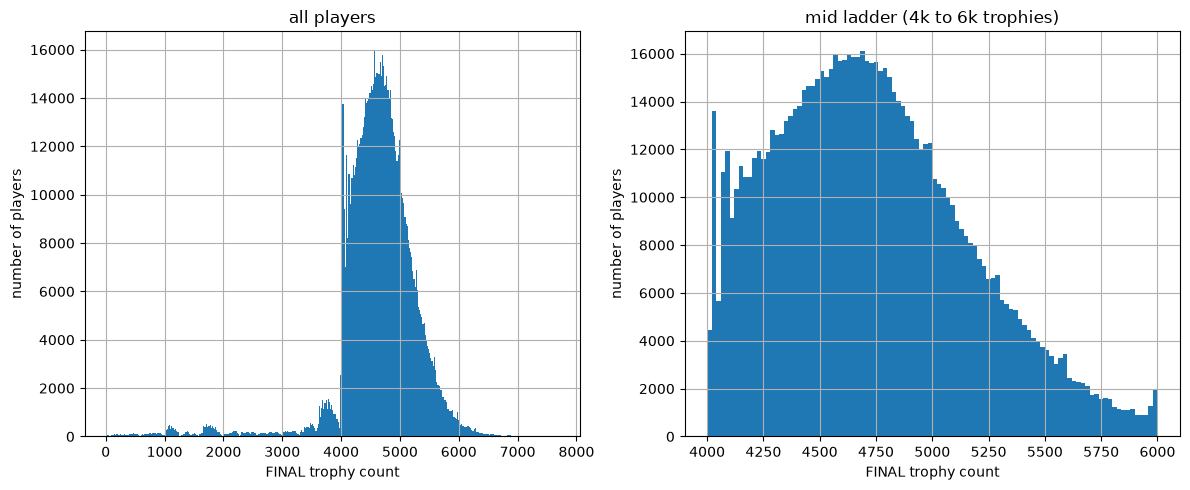

In [13]:
# distribution of all players according to their final trophy count
# we want the same width of bins relative to the x-axis for both plots
# all-player plot ranges from 0-8000 (8000), while mid-ladder ranges from 4000-6000 (2000)
# so all-player gets 4x more bins than mid-ladder

#idk if the above as necessary tho

plt.figure(figsize=(12,5))
ax1 = plt.subplot(1,2,1)
reshaped.sort_values("battleTime").drop_duplicates("user", keep="last")["trophies"].hist(bins=400, ax=ax1)
plt.title("all players")
plt.xlabel("FINAL trophy count")
plt.ylabel("number of players")

ax2 = plt.subplot(1,2,2)
mid_ladder.sort_values("battleTime").drop_duplicates("user", keep="last")["trophies"].hist(bins=100, ax=ax2)
plt.title("mid ladder (4k to 6k trophies)")
plt.xlabel("FINAL trophy count")
plt.ylabel("number of players")

plt.tight_layout()
plt.show()

Text(0, 0.5, 'Number of players')

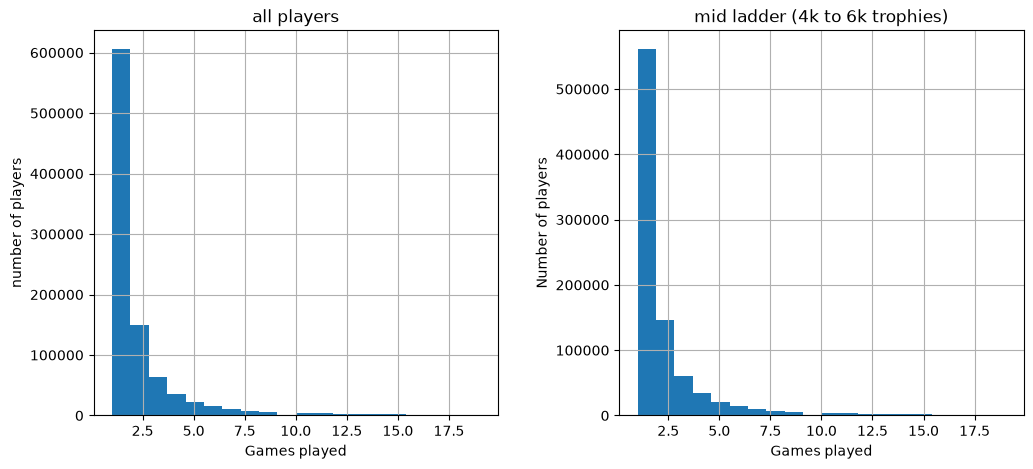

In [23]:
plt.figure(figsize=(12,5))
ax1 = plt.subplot(1,2,1)
all_count = reshaped.groupby("user")["trophies"].count().reset_index(name="count")
# all_count.describe()
all_count.loc[(all_count['count']<20)].hist(bins=20, ax=ax1)
plt.title("all players")
plt.xlabel("Games played")
plt.ylabel("number of players")

ax2 = plt.subplot(1,2,2)
mid_count = mid_ladder.groupby("user")["trophies"].count().reset_index(name="count")
mid_count.loc[(mid_count['count']<20)].hist(bins=20, ax=ax2)
plt.title("mid ladder (4k to 6k trophies)")
plt.xlabel("Games played")
plt.ylabel("Number of players")

# plt.tight_layout()
# plt.show()

In [26]:
all_count.describe()

,count
count,949311.000000
mean,2.329991
std,3.880940
min,1.000000
25%,1.000000
50%,1.000000
75%,2.000000
max,123.000000


# notes for calculating win rate
- When calculating the win rate per session, we want to make sure out player does not leave the 4000-6000 trophy range for the entire season. For example, if a player starts at 5999 and wins 1 game, then loses the next 100, his record will still be a 100% winrate by our table.
- We should also consider calculating the weighted sum of win rates, weighted on the games played per session. For example, 50/100 and 1/1 represent 50% and 100% win rates respectively, and naively averaging would give a 75% winrate, when in fact it makes more sense to weigh the 50/100 more (in fact, 100x more) than 1/1, which would give us 51/101 instead as the average winrate.
